# Algebra / Number Theory：SFT 前后 loss 变化的预实验

**Run：** `math-algebra-numbertheory-qwen25-1p5b-seed42`  
**结果时间（UTC）：** 2026-10-21T17:23:47.726111+00:00  
**模型：** `Qwen/Qwen2.5-1.5B-Instruct`；主报告 checkpoint：step 32。

本 notebook 将实验设置、结果、对照和局限放在一起。两项指标并列考察，不设主次：loss 下降量 ROC-AUC **0.6849**（95% CI 0.6534–0.7160）；相对下降比例 ROC-AUC **0.7007**（95% CI 0.6688–0.7314）。
指标是否优于基线以及长度控制后的表现，见后面的配对比较。

已保存执行输出，直接打开即可查看表格和图。重跑只读取同目录的 `snapshot/`，
不需要 GPU、checkpoint 或原始数据挂载，也不会重新训练模型。
来源路径、时间依据和快照 SHA-256 见 `manifest.json`。

## 1. 问题与评价约定

只在 A1 上做 SFT；A2 是未参与这次 SFT 的 A 域样本，B 是另一个域。
两个模型使用完全相同的 token IDs 和回答 mask，只计算回答正文的平均 token NLL（nats/token）。
A2 为正类，所有排序方向预先固定；A1 诊断样本不参与 A2/B 的分类评价。

下降量和相对下降比例并列考察，不设主次。

- loss 下降量：`delta_loss = L_ref - L_sft`。
- 相对下降比例：`relative_gain = (L_ref - L_sft) / max(L_ref, 1e-6)`。
- 基线：`-L_ref`、`-L_sft`，即 loss 低的样本优先；反向基线在附录单列。
- 95% 区间来自原始分析的 2,000 次按 domain 分层、按 group 重采样的 bootstrap。
  本 notebook 重算 AUC、AP 和 top-k 点估计并与快照交叉核对，直接展示原始区间。

这是**同域识别**预实验，不直接检验被选数据用于后续训练时的实际收益。

In [1]:
import hashlib
import json
import math
import os
import sys
import tempfile
from pathlib import Path

if 'MPLCONFIGDIR' not in os.environ:
    scratch = Path('/dev/shm/data-picking-runtime') if Path('/dev/shm').is_dir() else Path(tempfile.gettempdir()) / 'data-picking-runtime'
    os.environ['MPLCONFIGDIR'] = str(scratch / 'matplotlib')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 100)

In [2]:
candidates = [Path.cwd(), Path.cwd() / 'experiments-analysis' / '2026-10-21_172347Z_math-algebra-numbertheory-qwen25-1p5b-seed42']
HERE = next((p for p in candidates if (p / 'manifest.json').is_file() and (p / 'snapshot').is_dir()), None)
if HERE is None:
    raise FileNotFoundError('请将 notebook 工作目录设为本实验目录，或仓库根目录。')
SNAPSHOT = HERE / 'snapshot'
manifest = json.loads((HERE / 'manifest.json').read_text())
for name, info in manifest['files'].items():
    content = (SNAPSHOT / name).read_bytes()
    assert len(content) == info['bytes'], name
    assert hashlib.sha256(content).hexdigest() == info['sha256'], name

def load_json(name):
    return json.loads((SNAPSHOT / name).read_text())

metrics = load_json('metrics.json')
effective = load_json('effective_config.json')
completed = load_json('training_complete.json')
validation = load_json('validation_summary.json')
df = pd.read_parquet(SNAPSHOT / 'per_example.parquet')
training = pd.read_json(SNAPSHOT / 'train.jsonl', lines=True)
evaluation = df.loc[df['split'].isin(['A2', 'B'])].reset_index(drop=True)
matched_ids = load_json('length_matched_ids.json')
assert df['id'].is_unique
assert len(set(matched_ids)) == len(matched_ids)
assert set(matched_ids) <= set(evaluation['id'])
matched = evaluation.set_index('id').loc[matched_ids].reset_index()
assert len(evaluation) == metrics['main']['examples']
assert set(evaluation['split']) == {'A2', 'B'}
assert completed['global_step'] == metrics['checkpoint_step']
assert metrics['primary_checkpoint'] is True
print(f"快照校验通过；全部逐样本记录 {len(df)} 条，正式评估 {len(evaluation)} 条，长度匹配 {len(matched)} 条。")
print('Python:', sys.executable)

快照校验通过；全部逐样本记录 1152 条，正式评估 1024 条，长度匹配 808 条。
Python: /home/v-guanhechen/data-picking/.venv/bin/python


## 2. 实验设置与数据划分

In [3]:
cfg = effective['config']
settings = [
    ('模型', cfg['model']['name']),
    ('模型 revision', cfg['model']['revision']),
    ('数据源', cfg['data']['name']),
    ('数据 revision', cfg['data']['revision']),
    ('A / B', f"{cfg['data']['a_subset']} / {cfg['data']['b_subset']}"),
    ('划分 seed / 训练 seed', f"{cfg['data']['split_seed']} / {cfg['training']['seed']}"),
    ('训练规模', f"{effective['actual_train_size']} examples; {completed['seen_response_tokens']:,} response tokens"),
    ('训练长度', f"{cfg['training']['epochs']} epoch; {completed['global_step']} optimizer steps"),
    ('有效 batch / 学习率', f"{cfg['training']['effective_batch_size']} / {cfg['training']['learning_rate']}"),
    ('训练精度 / attention', f"{cfg['training']['parameter_dtype']} parameters + {cfg['training']['autocast_dtype']} autocast / {cfg['training']['attention_backend']}"),
    ('打分精度', cfg['scoring']['forward_dtype']),
    ('主报告 checkpoint', completed['global_step']),
]
display(pd.DataFrame(settings, columns=['设置', '值']))
splits = effective['data_summary']['splits']
display(pd.DataFrame([
    {'split': name, '条数': value['examples'], '回答 tokens': value['response_tokens'], **value['level_counts']}
    for name, value in splits.items()
]).set_index('split').fillna(0))
assert splits['A2']['level_counts'] == splits['B']['level_counts']
display(pd.DataFrame(effective['data_summary']['filter_counts']).fillna(0).astype(int).rename_axis('过滤 / 选择状态'))

,设置,值
0,模型,Qwen/Qwen2.5-1.5B-Instruct
1,模型 revision,989aa7980e4cf806f80c7fef2b1adb7bc71aa306
2,数据源,EleutherAI/hendrycks_math
3,数据 revision,21a5633873b6a120296cce3e2df9d5550074f4a3
4,A / B,algebra / number_theory
5,划分 seed / 训练 seed,2026 / 42
6,训练规模,"1024 examples; 138,236 response tokens"
7,训练长度,1 epoch; 32 optimizer steps
8,有效 batch / 学习率,32 / 2e-05
9,训练精度 / attention,float32 parameters + bfloat16 autocast / math


,条数,回答 tokens,Level 3,Level 4,Level 1,Level 2,Level 5
split,,,,,,,
A1,1024,138236,234,234,109,203,244
A2,512,70771,119,119,46,104,124
B,512,88882,119,119,46,104,124


,A,B
过滤 / 选择状态,,
selected,1536,512
eligible,93,345
image_or_diagram,79,3
duplicate_group_member,36,9


A2/B 的难度等级组成完全匹配。按规范化问题及字符 5-gram 相似度分组后，每组保留一个代表，
跨域重复组排除；图形表示、空内容和超长样本按同一规则过滤。
`eligible` 表示过滤后可用但未抽入本轮的样本。官方 test 没有用于这轮训练或打分。
这些措施不能保证排除所有语义重复，也未核验初始模型预训练是否包含 MATH。

## 3. 训练过程与两域 loss 变化

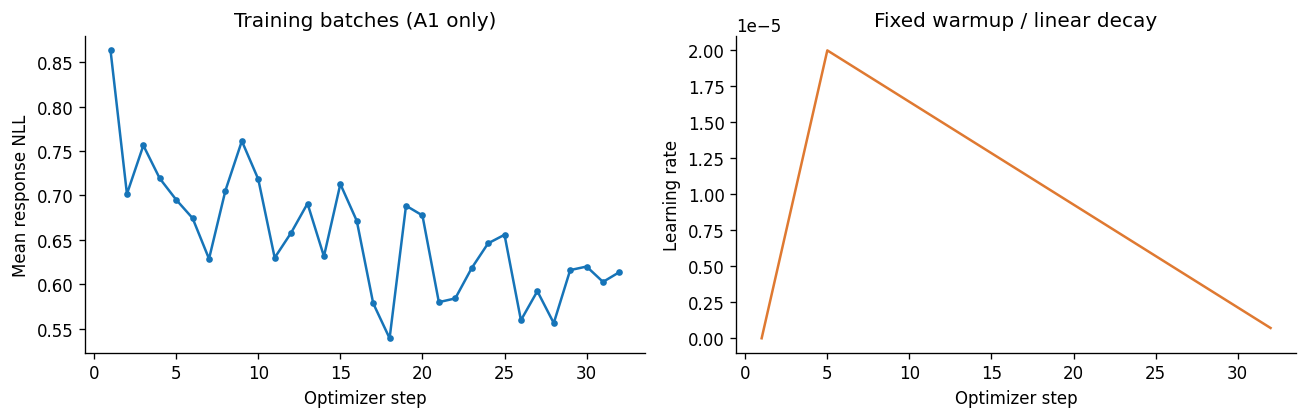

训练 step 记录的耗时合计 97.3 秒；不含模型加载、checkpoint I/O 和评分。


In [4]:
assert training['step'].tolist() == list(range(1, completed['global_step'] + 1))
assert np.isfinite(training[['loss', 'grad_norm']].to_numpy()).all()
assert int(training['response_tokens'].sum()) == completed['seen_response_tokens']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(training['step'], training['loss'], marker='.', color='#1674B8')
axes[0].set(xlabel='Optimizer step', ylabel='Mean response NLL', title='Training batches (A1 only)')
axes[1].plot(training['step'], training['lr'], color='#DF7931')
axes[1].set(xlabel='Optimizer step', ylabel='Learning rate', title='Fixed warmup / linear decay')
fig.tight_layout()
plt.show()
plt.close(fig)
print(f"训练 step 记录的耗时合计 {training['seconds'].sum():.1f} 秒；不含模型加载、checkpoint I/O 和评分。")

每一步的 batch 内容不同，因此训练曲线不等于固定评估集上的学习曲线。下面比较相同样本在两个模型下的 loss；A1 只展示固定的 128 条训练诊断样本。

,条数,ref NLL,SFT NLL,平均下降量,loss 下降样本比例
split,,,,,
A1_diagnostic,128,0.8214,0.5154,0.3060,1.0000
A2,512,0.8093,0.6374,0.1719,0.9746
B,512,0.8967,0.7959,0.1008,0.8809


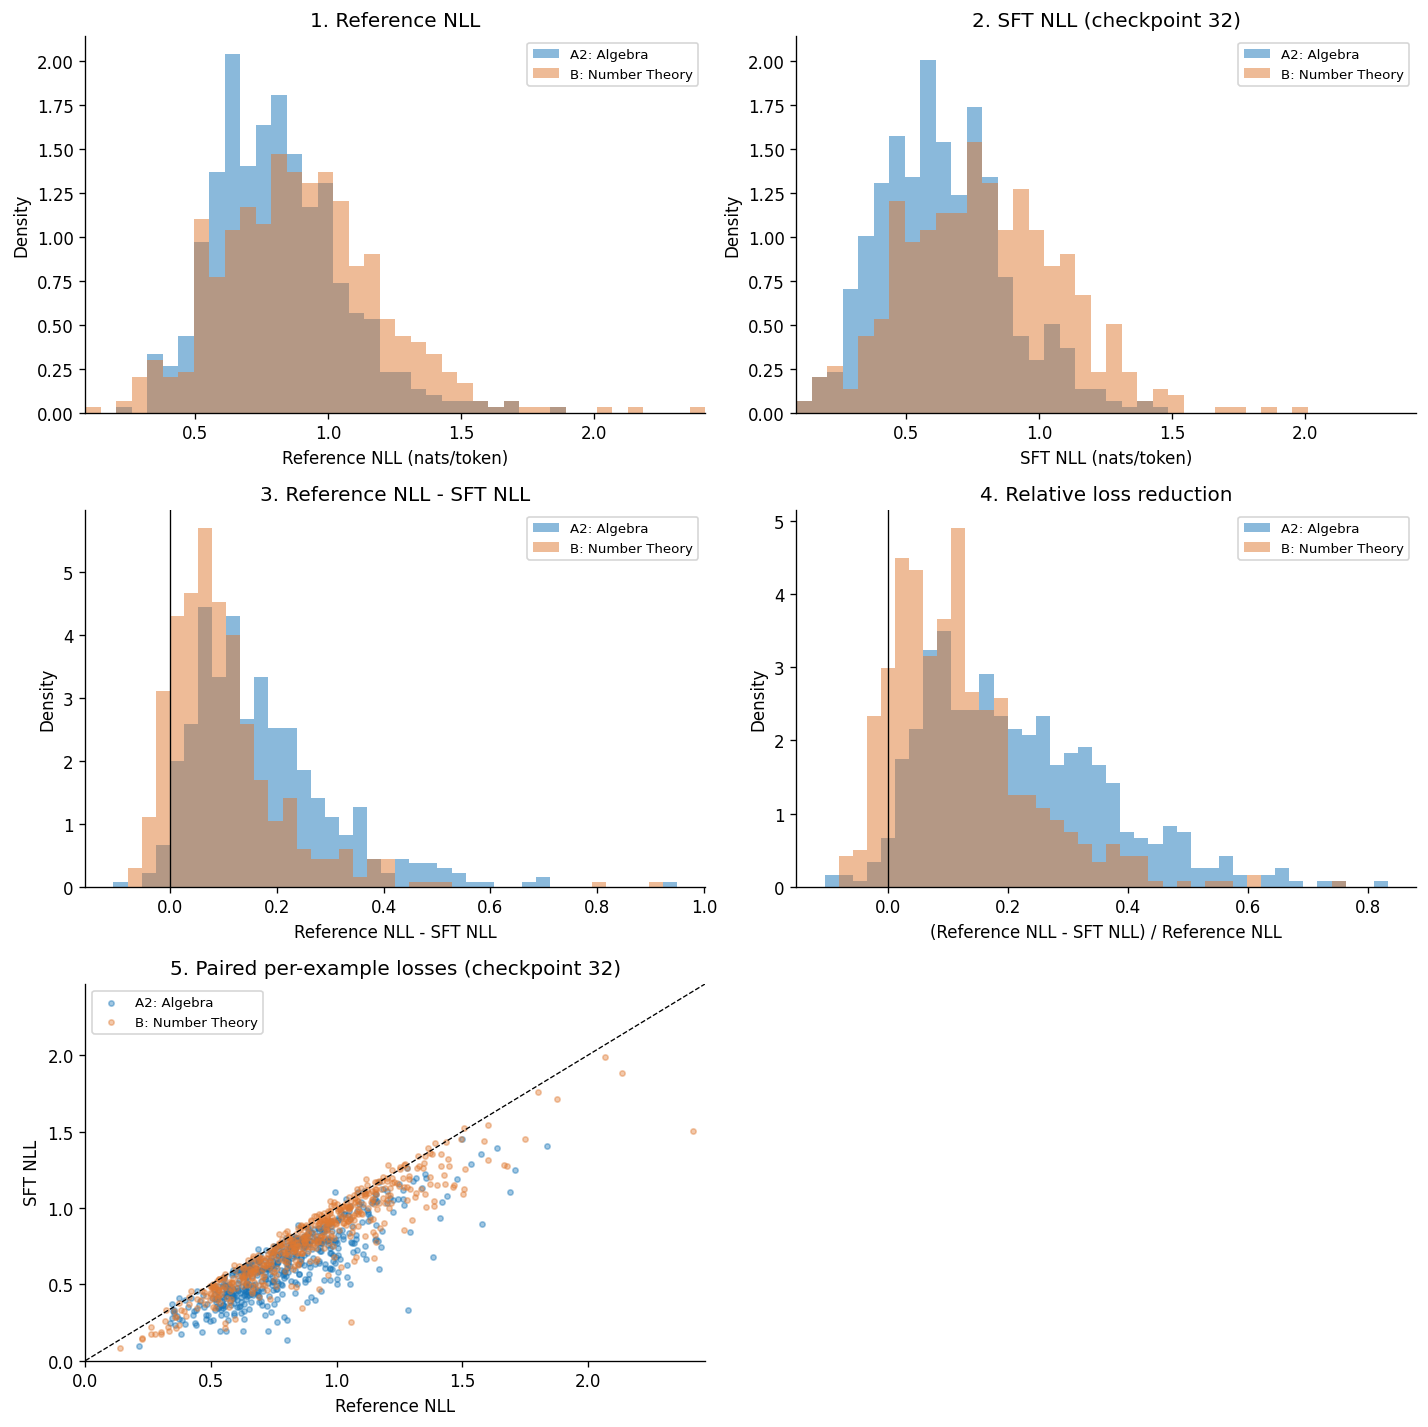

In [5]:
loss_table = pd.DataFrame([
    {'split': name, '条数': len(group), 'ref NLL': group['ref_mean_nll'].mean(),
     'SFT NLL': group['sft_mean_nll'].mean(), '平均下降量': group['delta_loss'].mean(),
     'loss 下降样本比例': (group['delta_loss'] > 0).mean()}
    for name, group in df.groupby('split', sort=True)
]).set_index('split')
display(loss_table.round(4))
colors = {'A': '#1674B8', 'B': '#DF7931'}
domain_names = {'A': 'A2: ' + cfg['data']['a_subset'].replace('_', ' ').title(),
                'B': 'B: ' + cfg['data']['b_subset'].replace('_', ' ').title()}
scoring_steps = evaluation['checkpoint_step'].unique()
assert len(scoring_steps) == 1, 'Expected one SFT checkpoint for the paired comparison'
sft_step = int(scoring_steps[0])
assert sft_step == completed['global_step']

fig = plt.figure(figsize=(12, 12))
grid = fig.add_gridspec(3, 2)
axes = [fig.add_subplot(grid[row, col]) for row in range(2) for col in range(2)]
axes.append(fig.add_subplot(grid[2, 0]))

# Use the same NLL bins for both models and both domains.
nll_bins = np.histogram_bin_edges(
    evaluation[['ref_mean_nll', 'sft_mean_nll']].to_numpy().ravel(), bins=40)
distributions = [
    ('ref_mean_nll', 'Reference NLL (nats/token)', '1. Reference NLL'),
    ('sft_mean_nll', 'SFT NLL (nats/token)', f'2. SFT NLL (checkpoint {sft_step})'),
    ('delta_loss', 'Reference NLL - SFT NLL', '3. Reference NLL - SFT NLL'),
    ('relative_gain', '(Reference NLL - SFT NLL) / Reference NLL', '4. Relative loss reduction'),
]
for ax, (column, xlabel, title) in zip(axes[:4], distributions):
    bins = nll_bins if column in {'ref_mean_nll', 'sft_mean_nll'} else np.histogram_bin_edges(evaluation[column], bins=40)
    for domain, group in evaluation.groupby('domain'):
        ax.hist(group[column], bins=bins, density=True, alpha=0.5,
                label=domain_names[domain], color=colors[domain])
    if column in {'delta_loss', 'relative_gain'}:
        ax.axvline(0, color='black', linewidth=0.8)
    ax.set(xlabel=xlabel, ylabel='Density', title=title)

nll_ymax = max(ax.get_ylim()[1] for ax in axes[:2])
for ax in axes[:2]:
    ax.set_xlim(nll_bins[0], nll_bins[-1])
    ax.set_ylim(0, nll_ymax)

for domain, group in evaluation.groupby('domain'):
    axes[4].scatter(group['ref_mean_nll'], group['sft_mean_nll'], s=10, alpha=0.4,
                    label=domain_names[domain], color=colors[domain])
bound = evaluation[['ref_mean_nll', 'sft_mean_nll']].to_numpy().max() * 1.02
axes[4].plot([0, bound], [0, bound], 'k--', linewidth=0.8)
axes[4].set(xlabel='Reference NLL', ylabel='SFT NLL',
            title=f'5. Paired per-example losses (checkpoint {sft_step})',
            xlim=(0, bound), ylim=(0, bound))
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

## 4. 能否把 A2 排在 B 前面？

In [6]:
score_keys = ['delta_loss', 'relative_gain', 'neg_ref_loss', 'neg_sft_loss']
score_labels = {'delta_loss': 'loss 下降量', 'relative_gain': '相对下降比例',
                'neg_ref_loss': 'ref loss，低值优先', 'neg_sft_loss': 'SFT loss，低值优先'}

def point_metrics(frame, key, ties):
    y = (frame['domain'] == 'A').to_numpy(dtype=int)
    scores = frame[key].to_numpy()
    order = np.lexsort((ties, -scores))
    return {'roc_auc': roc_auc_score(y, scores),
            'precision_top_10pct': y[order[:math.ceil(len(y) * .1)]].mean(),
            'precision_top_20pct': y[order[:math.ceil(len(y) * .2)]].mean()}

for frame, stored in [(evaluation, metrics['main']), (matched, metrics['length_matched'])]:
    ties = np.random.default_rng(cfg['analysis']['bootstrap_seed'] + 1).random(len(frame))
    for key in score_keys:
        for name, value in point_metrics(frame, key, ties).items():
            np.testing.assert_allclose(value, stored['scores'][key][name], rtol=0, atol=1e-12)

def interval(values):
    return f'[{values[0]:.4f}, {values[1]:.4f}]'

def metric_table(result, keys=score_keys):
    records = []
    for key in keys:
        row = result['scores'][key]
        records.append({'排序指标': score_labels.get(key, key), 'ROC-AUC': round(row['roc_auc'], 4),
                        'Top 10% A2': f"{row['precision_top_10pct']:.1%}",
                        'Top 20% A2': f"{row['precision_top_20pct']:.1%}"})
    return pd.DataFrame(records).set_index('排序指标')

display(metric_table(metrics['main']))
print('原始池和长度匹配池的 AUC、top-k 点估计均已重新计算，并与快照一致。')
print(f"原始池 top 10% 取前 {math.ceil(len(evaluation) * .1)} 条；A2/B 各占一半，随机 A2 占比期望为 50%。")

,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
loss 下降量,0.6849,70.9%,72.7%
相对下降比例,0.7007,77.7%,76.6%
ref loss，低值优先,0.5922,45.6%,56.1%
SFT loss，低值优先,0.6645,68.0%,67.8%


原始池和长度匹配池的 AUC、top-k 点估计均已重新计算，并与快照一致。
原始池 top 10% 取前 103 条；A2/B 各占一半，随机 A2 占比期望为 50%。


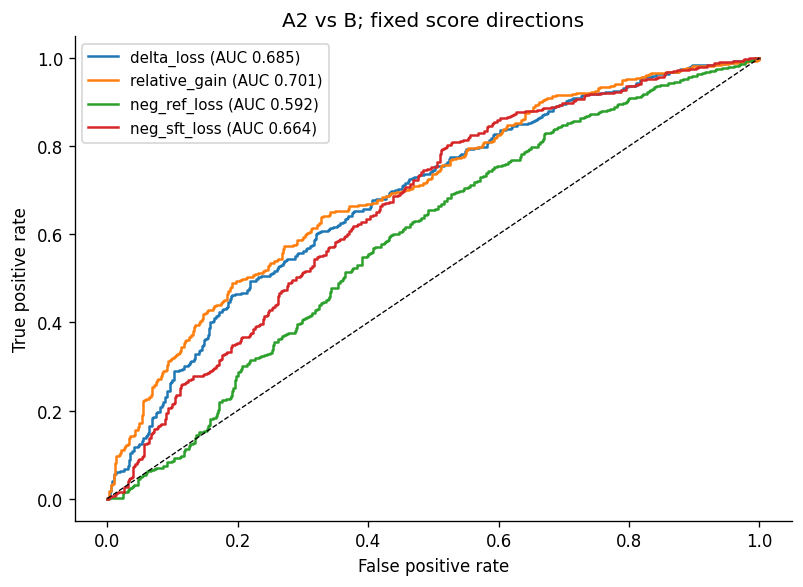

In [7]:
y = (evaluation['domain'] == 'A').to_numpy(dtype=int)
fig, ax = plt.subplots(figsize=(6.8, 5))
for key in score_keys:
    fpr, tpr, _ = roc_curve(y, evaluation[key])
    ax.plot(fpr, tpr, label=f"{key} (AUC {metrics['main']['scores'][key]['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='A2 vs B; fixed score directions')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. 长度控制及相对基线的增益

原始分析按混合池的 prompt/response 长度四分位建立联合分桶，每桶从两域各取相同数量，
未使用模型分数挑样本。下面读取保存的匹配 ID，展示同一份控制样本。
匹配改变了评估人群，且分桶不能保证完全消除长度或其他混杂因素。

In [8]:
print(f"匹配保留 {len(matched)}/{len(evaluation)} 条（{len(matched)/len(evaluation):.1%}）。")
display(pd.DataFrame({'原始池': evaluation.groupby('domain').size(),
                      '长度匹配': matched.groupby('domain').size()}))
display(metric_table(metrics['length_matched']))
length_rows = []
for pool, result in [('原始池', metrics['main']), ('长度匹配', metrics['length_matched'])]:
    for column, values in result['length_baselines'].items():
        length_rows.append({'评估集': pool, '长度特征': column, '+长度 AUC': values['positive_auc'], '-长度 AUC': values['negative_auc']})
display(pd.DataFrame(length_rows).round(4))

匹配保留 808/1024 条（78.9%）。


,原始池,长度匹配
domain,,
A,512,404
B,512,404


,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
loss 下降量,0.6524,66.7%,67.9%
相对下降比例,0.6770,76.5%,74.1%
ref loss，低值优先,0.6138,44.4%,55.6%
SFT loss，低值优先,0.6707,69.1%,64.2%


,评估集,长度特征,+长度 AUC,-长度 AUC
0,原始池,prompt_tokens,0.5510,0.4490
1,原始池,response_tokens,0.4099,0.5901
2,长度匹配,prompt_tokens,0.5006,0.4994
3,长度匹配,response_tokens,0.4885,0.5115


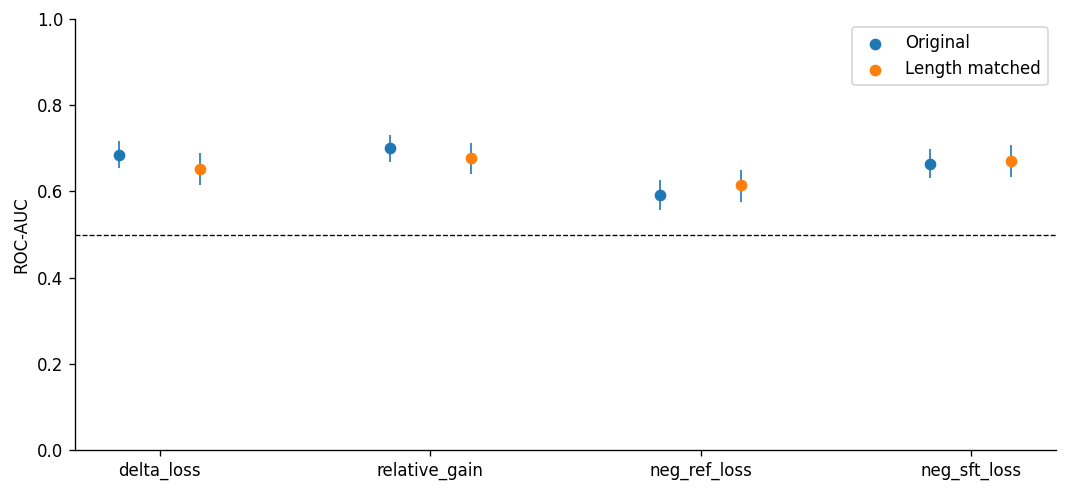

,评估集,比较,AUC 差,配对 95% CI,区间覆盖 0
0,原始池,delta_loss − neg_ref_loss,0.0927,"[0.0394, 0.1450]",False
1,原始池,delta_loss − neg_sft_loss,0.0204,"[-0.0228, 0.0629]",True
2,长度匹配,delta_loss − neg_ref_loss,0.0387,"[-0.0192, 0.0966]",True
3,长度匹配,delta_loss − neg_sft_loss,-0.0183,"[-0.0646, 0.0281]",True


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for shift, pool, result in [(-0.15, 'Original', metrics['main']), (.15, 'Length matched', metrics['length_matched'])]:
    positions = np.arange(len(score_keys)) + shift
    values = [result['scores'][k]['roc_auc'] for k in score_keys]
    ax.scatter(positions, values, label=pool, zorder=3)
    for position, key in zip(positions, score_keys):
        low, high = result['scores'][key]['roc_auc_ci95']
        ax.vlines(position, low, high, linewidth=1)
ax.axhline(.5, linestyle='--', color='black', linewidth=.8)
ax.set(xticks=np.arange(len(score_keys)), xticklabels=score_keys, ylabel='ROC-AUC', ylim=(0, 1))
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

comparisons = []
for pool, result in [('原始池', metrics['main']), ('长度匹配', metrics['length_matched'])]:
    for baseline in ['neg_ref_loss', 'neg_sft_loss']:
        value = result['paired_delta_auc_minus_baseline'][baseline]
        low, high = value['ci95']
        comparisons.append({'评估集': pool, '比较': 'delta_loss − ' + baseline,
                            'AUC 差': round(value['difference'], 4), '配对 95% CI': interval(value['ci95']),
                            '区间覆盖 0': low <= 0 <= high})
display(pd.DataFrame(comparisons))

## 6. 结论与边界

In [10]:
texts = []
for key in ['delta_loss', 'relative_gain']:
    value = metrics['main']['scores'][key]
    lo, hi = value['roc_auc_ci95']
    signal = ('在固定方向上有区分信号' if lo > .5 else
              '区分方向与预设假设相反，没有事后翻转分数' if hi < .5 else
              '区间覆盖 0.5，尚无稳定的区分证据')
    texts.append(f"{score_labels[key]}：AUC {value['roc_auc']:.4f}，95% CI {interval(value['roc_auc_ci95'])}；{signal}。")
a2, b = metrics['loss_summary']['A2'], metrics['loss_summary']['B']
texts.append(f"A2 平均 NLL：{a2['ref_mean_nll']['mean']:.4f} → {a2['sft_mean_nll']['mean']:.4f}；"
             f"B：{b['ref_mean_nll']['mean']:.4f} → {b['sft_mean_nll']['mean']:.4f}。")
if a2['delta_loss']['mean'] > 0 and b['delta_loss']['mean'] > 0:
    texts.append('两个域的平均 loss 都下降，区分效果没有依赖 B 的平均 loss 恶化。')
for key in ['delta_loss', 'relative_gain']:
    v = metrics['length_matched']['scores'][key]
    texts.append(f"长度匹配后，{score_labels[key]} AUC 为 {v['roc_auc']:.4f}，95% CI {interval(v['roc_auc_ci95'])}。")
for label, result, baseline in [('loss 下降量在原始池中与 SFT loss 比较', metrics['main'], 'neg_sft_loss'),
                                 ('loss 下降量在长度匹配后与 ref loss 比较', metrics['length_matched'], 'neg_ref_loss')]:
    value = result['paired_delta_auc_minus_baseline'][baseline]
    lo, hi = value['ci95']
    if lo <= 0 <= hi:
        texts.append(f"{label}：配对区间覆盖 0，额外区分收益尚不确定。")
    else:
        texts.append(f"{label}：AUC 差 {value['difference']:.4f}，95% CI {interval(value['ci95'])}。")
best = max(score_keys, key=lambda k: metrics['main']['scores'][k]['roc_auc'])
texts.append(f"本轮 {score_labels[best]} 的 AUC 点估计最高；这不自动证明它显著优于其他指标。")
display(Markdown('\n\n'.join(texts)))

loss 下降量：AUC 0.6849，95% CI [0.6534, 0.7160]；在固定方向上有区分信号。

相对下降比例：AUC 0.7007，95% CI [0.6688, 0.7314]；在固定方向上有区分信号。

A2 平均 NLL：0.8093 → 0.6374；B：0.8967 → 0.7959。

两个域的平均 loss 都下降，区分效果没有依赖 B 的平均 loss 恶化。

长度匹配后，loss 下降量 AUC 为 0.6524，95% CI [0.6150, 0.6884]。

长度匹配后，相对下降比例 AUC 为 0.6770，95% CI [0.6408, 0.7131]。

loss 下降量在原始池中与 SFT loss 比较：配对区间覆盖 0，额外区分收益尚不确定。

loss 下降量在长度匹配后与 ref loss 比较：配对区间覆盖 0，额外区分收益尚不确定。

本轮 相对下降比例 的 AUC 点估计最高；这不自动证明它显著优于其他指标。

本轮只有一个模型、一个训练 seed 和一次数据划分；bootstrap 区间不包含训练随机性。
平衡评估池上的 AP/top-k 占比也不能直接外推到其他 A/B 比例的候选池。

后续可做（本轮未运行）：固定方案补独立 seed/划分，再在未参与选择的 A_test 上比较
按不同分数和随机方法选数后的实际训练收益，匹配训练 token 预算。

## 7. 验证记录与原始产物

In [11]:
display(pd.DataFrame([
    ('保存 optimizer / 自动恢复', f"{effective['save_optimizer']} / {effective['auto_resume']}"),
    ('真实续训检查', validation['real_resume']['passed']),
    ('核心 / 分析测试', f"{validation['unit_tests']['core_passed']} / {validation['unit_tests']['analysis_passed']}"),
    ('同模型重复评分最大差', validation['scoring_sanity']['identical_model_max_delta']),
    ('batch / padding 最大差', validation['scoring_sanity']['batch_padding_max_delta']),
    ('相对下降分母保护触发数', metrics['relative_gain_denominator_clamps']),
], columns=['检查', '结果']))
print('原始 run：', manifest['source_run_dir'])
print('最终 checkpoint：', completed['checkpoint'])
print('训练 fingerprint：', effective['training_fingerprint'])
print('时间来源：', manifest['timestamp_basis'])
print('快照文件 SHA-256：')
display(pd.DataFrame([{'文件': name, 'bytes': info['bytes'], 'SHA-256': info['sha256']}
                       for name, info in manifest['files'].items()]).set_index('文件'))

,检查,结果
0,保存 optimizer / 自动恢复,True / True
1,真实续训检查,True
2,核心 / 分析测试,4 / 2
3,同模型重复评分最大差,0.0
4,batch / padding 最大差,0.000003
5,相对下降分母保护触发数,0


原始 run： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-qwen25-1p5b-seed42
最终 checkpoint： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-qwen25-1p5b-seed42/checkpoints/step-000032-1d6e5f24
训练 fingerprint： 22d1d362f09e21e1ab1995af3261db33a10ee4573549c0cd623a64d0610ab1be
时间来源： metrics/metrics.json filesystem modification time captured at first export; proxy for original analysis completion, not export time
快照文件 SHA-256：


,bytes,SHA-256
文件,,
metrics.json,16952,db88b2eae90bc49c738005846306d3312e932d2405de8e3ff0f998b1c0906c1f
per_example.parquet,340681,1c52b3d31d3ec20df36a740495e8770a457ce86fe8f55aeab49960d7d2a4eec2
length_matched_ids.json,21108,15ac0a9c155195b4e2cdde6abd36d16b421154b3fa62960592e41cc4565163ca
effective_config.json,37891,77b1ac90935052496f3e256faf7581368cacc668a53731abcdaa5008d1326676
training_complete.json,275,e412bde65bca5db9f5d373fe911ffe428fa7fe92e1745536ea3210a6e50237bb
validation_summary.json,1510,5c094b764cf10619fa5f371ec792c650febfee9c877a2e75e6c29f7eb9a57bcf
train.jsonl,5959,ed7d71c19a71272f636aa7f510f28718b9983d672a407ac1cef542803e9595e3
gradient_per_example.parquet,433573,d1121724f798f70fe9dbcd8ddd73e998b84f5228c1923f787cc69d50177f1066
gradient_per_layer.parquet,1738690,70cce46bb5a7a9b15781b1fb0dd9bf4ac82c3babc7f45692aca980b7325954ab


训练在当前本地 PyTorch/CUDA 环境中固定使用 SDPA math 后端，避免自动后端在检查中出现的非有限梯度。
评分使用完整 float32，因为 bf16 在不同 batch/padding 下曾出现约 0.0047 nats/token 的差异。
这些数值修正发生在正式训练和域区分分析之前，没有依据 A2/B 的效果调整超参数。

模型权重、optimizer、数据下载和 token 缓存保留在原始挂载。
本目录只包含用于 review 的 notebook 和小体积结果快照。

## 附录：预先规定的反向原始 loss 基线

In [12]:
display(metric_table(metrics['main'], keys=['pos_ref_loss', 'pos_sft_loss']))

,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
pos_ref_loss,0.4078,30.1%,33.7%
pos_sft_loss,0.3355,22.3%,25.4%


## 8. 训练前后的逐样本梯度分析

下文是新增的探索性诊断，沿用上文同一批两域样本、reference 和 step 32 SFT 模型。
对每条样本的**回答正文平均 token NLL**计算 `g(x) = ∇θ L(x)`；完整 float32、eval 模式、SDPA math，
梯度不裁剪，没有 optimizer step，绑定参数只计一次。数据已经测量并保存，本节重跑仅需 CPU。

- 全局 norm：`||g||₂`；RMS 为 `||g||₂ / √参数量`。两模型参数量相同，二者的排序信息相同。
- 最大绝对梯度：`max |gᵢ|`，对应单个标量参数；逐参数张量统计另列。
- 层间分布：每层 RMS 和每层所占的梯度平方范数比例。
- 方向相似度：样本梯度与**同一模型上固定 128 条 A1 平均梯度**的 cosine。

norm 的前后差是两个 norm 的差，不能解释成两个梯度向量之差的 norm。
loss 下降量与相对下降比例仍按上文并列考察；本节不会用梯度诊断替换它们。

In [13]:
GRADIENT_DIRECTORY = '2026-10-21_172347Z_math-algebra-numbertheory-qwen25-1p5b-seed42'

import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score
%matplotlib inline
GROOT = next((p for p in [Path.cwd(),Path.cwd()/'experiments-analysis'/GRADIENT_DIRECTORY]
              if (p/'snapshot/gradient_metrics.json').is_file()),None)
if GROOT is None: raise FileNotFoundError('请使用当前实验目录或仓库根目录作为工作目录。')
GMANIFEST = json.loads((GROOT/'manifest.json').read_text())
for name in ['gradient_metrics.json','gradient_per_example.parquet','gradient_per_layer.parquet',
             'gradient_parameter_summary.parquet','gradient_provenance.json']:
    raw = (GROOT/'snapshot'/name).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==GMANIFEST['files'][name]['sha256'],name
gm = json.loads((GROOT/'snapshot/gradient_metrics.json').read_text())
gd = pd.read_parquet(GROOT/'snapshot/gradient_per_example.parquet')
gl = pd.read_parquet(GROOT/'snapshot/gradient_per_layer.parquet')
gp = pd.read_parquet(GROOT/'snapshot/gradient_parameter_summary.parquet')
gmatched = gd.set_index('id').loc[gm['length_matched_ids']].reset_index()
gdomains = gm['domains'];gnames = gm['domain_names']
gcolors = {'A':'#1674B8',gdomains[1]:'#DF7931'}
gshort = {d:('A2' if d=='A' else gnames[d].split(': ',1)[1]) for d in gdomains}
assert gd.id.is_unique and gd.groupby('domain').size().to_dict()=={d:512 for d in gdomains}
assert set(gl.id)==set(gd.id) and set(gp.domain)==set(gdomains)
assert gm['checkpoint_step']==32
assert max(gm['nll_difference_from_loss_notebook'].values())<=gm['nll_crosscheck_tolerance']
gfigures = []
print('梯度数据来源：',gm['measurement_run'])
print('全参数数量（绑定权重只计一次）：',f"{gm['parameter_count']:,}")
print('与上文 loss 最大数值复核差：',gm['nll_difference_from_loss_notebook'])
print('这些差异来自原有单样本/批量 FP32 计算路径；本节未改写上文的 loss 数据。')

梯度数据来源： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-dolly-lengthonly-qwen25-1p5b-seed42
全参数数量（绑定权重只计一次）： 1,543,714,304
与上文 loss 最大数值复核差： {'ref': 2.384185791015625e-05, 'sft': 3.039836883544922e-06}
这些差异来自原有单样本/批量 FP32 计算路径；本节未改写上文的 loss 数据。


### 8.1 全局梯度大小、最大值及前后变化

,数据,模型,样本数,norm 均值,norm 中位数,norm Q25,norm Q75,RMS 中位数,max|g| 中位数
0,A2: Algebra,ref,512,22.3597,19.1785,14.4551,26.5516,4.881e-04,1.8033
1,A2: Algebra,sft,512,13.2167,11.9302,9.7128,15.5442,3.036e-04,1.7030
2,B: Number Theory,ref,512,20.0502,17.5922,12.8873,24.3647,4.478e-04,1.7325
3,B: Number Theory,sft,512,13.9562,12.8859,10.0690,16.6981,3.280e-04,1.7483


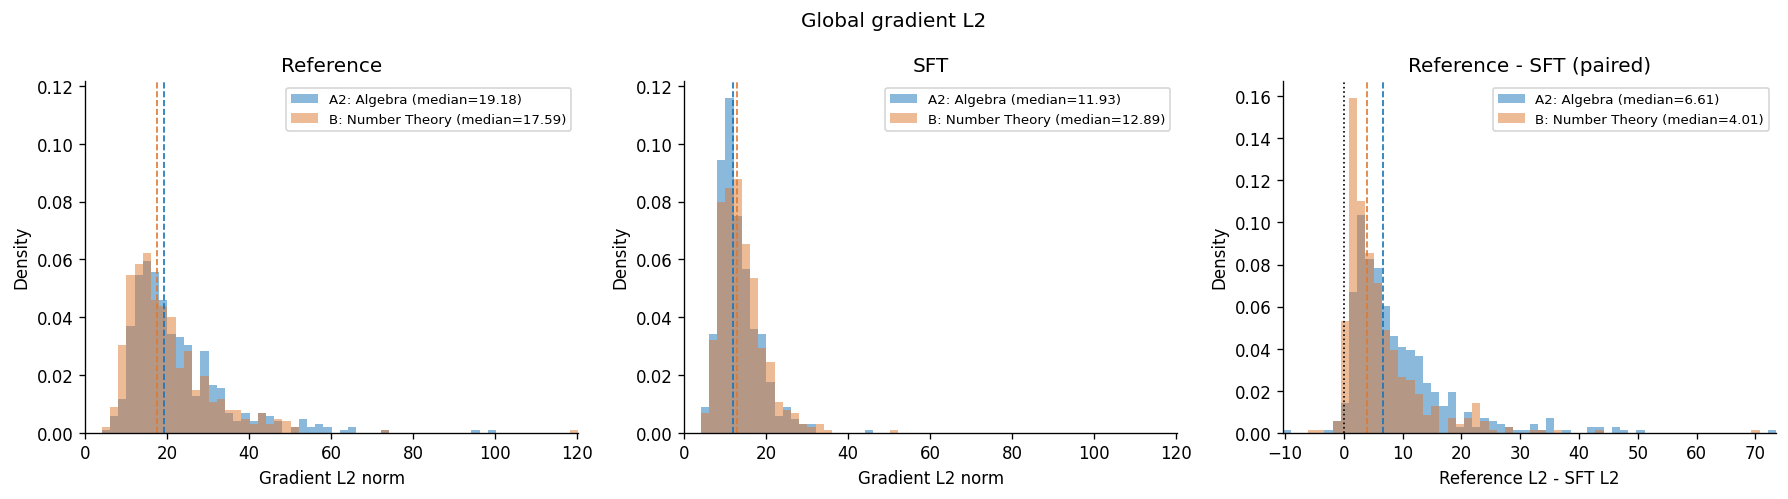

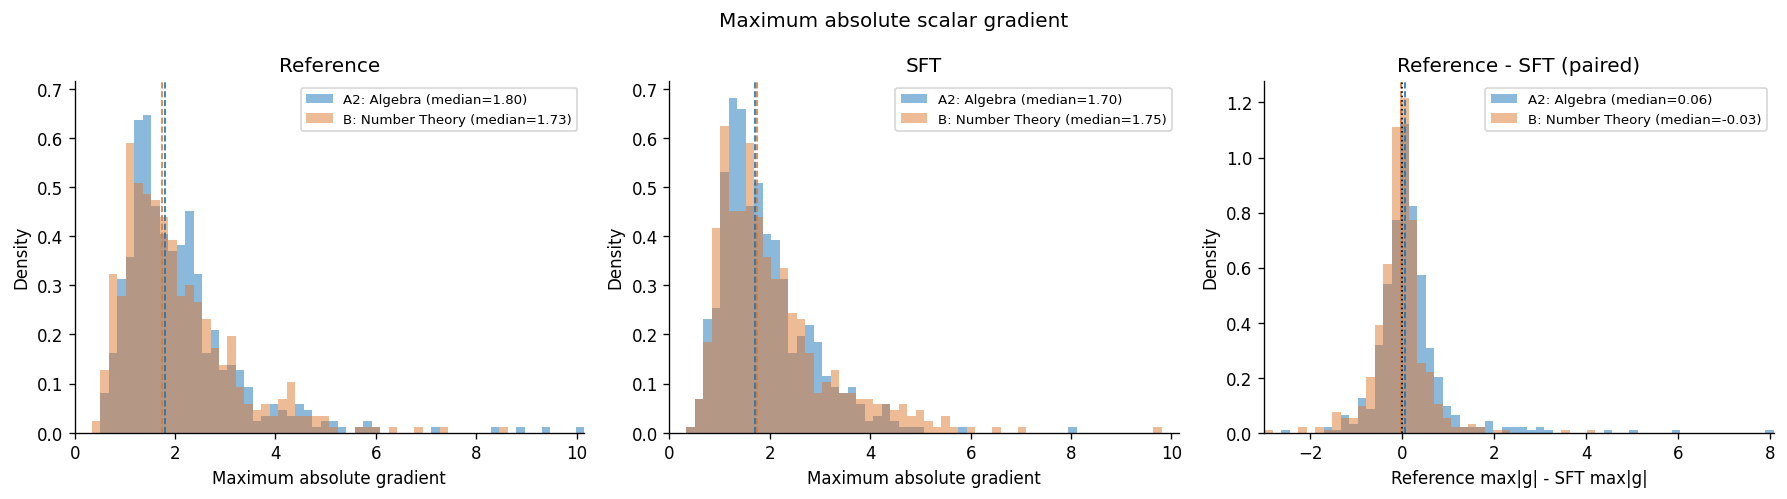

,指标,数据,ref 中位数,SFT 中位数,配对差值中位数,差值 > 0 比例
0,global gradient L2,A2: Algebra,19.1785,11.9302,6.6052,0.9863
1,global gradient L2,B: Number Theory,17.5922,12.8859,4.0053,0.9824
2,maximum absolute gradient,A2: Algebra,1.8033,1.7030,0.0585,0.5781
3,maximum absolute gradient,B: Number Theory,1.7325,1.7483,-0.0322,0.4316


**观测：**

A2: Algebra 的 global gradient L2：ref/SFT 中位数为 19.1785/11.9302；逐样本 ref−SFT 差值的中位数为 6.6052，98.6% 的样本差值为正。

B: Number Theory 的 global gradient L2：ref/SFT 中位数为 17.5922/12.8859；逐样本 ref−SFT 差值的中位数为 4.0053，98.2% 的样本差值为正。

两域 global gradient L2 的中位数差（A2−Number Theory）从 ref 的 1.5864 变为 SFT 的 -0.9557；这是中位数的位置差，分布形状见图。

A2: Algebra 的 maximum absolute gradient：ref/SFT 中位数为 1.8033/1.7030；逐样本 ref−SFT 差值的中位数为 0.0585，57.8% 的样本差值为正。

B: Number Theory 的 maximum absolute gradient：ref/SFT 中位数为 1.7325/1.7483；逐样本 ref−SFT 差值的中位数为 -0.0322，43.2% 的样本差值为正。

两域 maximum absolute gradient 的中位数差（A2−Number Theory）从 ref 的 0.0709 变为 SFT 的 -0.0453；这是中位数的位置差，分布形状见图。

In [14]:
grow = []
for domain,group in gd.groupby('domain'):
    for prefix in ['ref','sft']:
        norm = group[f'{prefix}_grad_l2']
        grow.append({'数据':gnames[domain],'模型':prefix,'样本数':len(group),
                     'norm 均值':norm.mean(),'norm 中位数':norm.median(),
                     'norm Q25':norm.quantile(.25),'norm Q75':norm.quantile(.75),
                     'RMS 中位数':group[f'{prefix}_grad_rms'].median(),
                     'max|g| 中位数':group[f'{prefix}_grad_max_abs'].median()})
# Plain DataFrame display works without pandas' optional Jinja2/Styler dependency.
gsummary = pd.DataFrame(grow)
gsummary_display = gsummary.copy()
for column,pattern in {'norm 均值':'{:.4f}','norm 中位数':'{:.4f}',
                      'norm Q25':'{:.4f}','norm Q75':'{:.4f}',
                      'RMS 中位数':'{:.3e}','max|g| 中位数':'{:.4f}'}.items():
    gsummary_display[column] = gsummary_display[column].map(pattern.format)
display(gsummary_display)
# Each metric gets three overlaid two-domain distributions, in the same order.
for key,title,xlabel in [('grad_l2','Global gradient L2','Gradient L2 norm'),
                         ('grad_max_abs','Maximum absolute scalar gradient','Maximum absolute gradient')]:
    value_bins = np.linspace(0,gd[[f'ref_{key}',f'sft_{key}']].to_numpy().max(),61)
    paired_difference = gd[f'ref_{key}']-gd[f'sft_{key}']
    difference_bins = np.histogram_bin_edges(paired_difference,bins=60)
    fig,axes = plt.subplots(1,3,figsize=(15,4.2))
    for ax,stage in zip(axes,['ref','sft','difference']):
        bins = difference_bins if stage=='difference' else value_bins
        for domain,group in gd.groupby('domain'):
            values = (group[f'ref_{key}']-group[f'sft_{key}'] if stage=='difference'
                      else group[f'{stage}_{key}'])
            median = values.median()
            assert np.histogram(values,bins=bins)[0].sum()==len(values)
            ax.hist(values,bins=bins,density=True,alpha=.5,color=gcolors[domain],
                    label=f'{gnames[domain]} (median={median:.2f})')
            ax.axvline(median,color=gcolors[domain],linestyle='--',linewidth=1)
        ax.set(xlim=(bins[0],bins[-1]),ylabel='Density')
        if stage=='difference':
            ax.axvline(0,color='black',linestyle=':',linewidth=1)
            difference_label = 'Reference L2 - SFT L2' if key=='grad_l2' else 'Reference max|g| - SFT max|g|'
            ax.set(title='Reference - SFT (paired)',xlabel=difference_label)
        else:
            ax.set(title='Reference' if stage=='ref' else 'SFT',xlabel=xlabel)
        ax.legend(fontsize=8)
    value_ymax = max(ax.get_ylim()[1] for ax in axes[:2])
    for ax in axes[:2]: ax.set_ylim(0,value_ymax)
    fig.suptitle(title,fontsize=12)
    fig.tight_layout();plt.show();plt.close(fig)
gchanges=[];gnotes=[]
for key,label in [('grad_l2','global gradient L2'),('grad_max_abs','maximum absolute gradient')]:
    for domain,group in gd.groupby('domain'):
        before,after = group[f'ref_{key}'],group[f'sft_{key}']
        difference = before-after
        fraction = (difference>0).mean()
        gchanges.append({'指标':label,'数据':gnames[domain],'ref 中位数':before.median(),
                         'SFT 中位数':after.median(),'配对差值中位数':difference.median(),'差值 > 0 比例':fraction})
        gnotes.append(f"{gnames[domain]} 的 {label}：ref/SFT 中位数为 {before.median():.4f}/{after.median():.4f}；"
                      f"逐样本 ref−SFT 差值的中位数为 {difference.median():.4f}，{fraction:.1%} 的样本差值为正。")
    target_group,other_group = gd.loc[gd.domain=='A'],gd.loc[gd.domain==gdomains[1]]
    ref_gap = target_group[f'ref_{key}'].median()-other_group[f'ref_{key}'].median()
    sft_gap = target_group[f'sft_{key}'].median()-other_group[f'sft_{key}'].median()
    gnotes.append(f"两域 {label} 的中位数差（A2−{gshort[gdomains[1]]}）从 ref 的 {ref_gap:.4f} 变为 SFT 的 {sft_gap:.4f}；这是中位数的位置差，分布形状见图。")
display(pd.DataFrame(gchanges).round(4))
display(Markdown('**观测：**\n\n'+'\n\n'.join(gnotes)))

每项指标依次展示 ref、SFT、逐样本 ref−SFT 的两域叠加分布，共六张分布图。
直方图使用全部样本、线性坐标和每域归一化的密度；同一指标的 ref/SFT 共用分桶、横轴范围和纵轴尺度，
两域在差值图中也共用分桶。彩色虚线表示各域中位数，差值图的黑色点线表示零。
正差值表示 SFT 后该指标下降；负差值表示上升。
本节展示原始评估池，长度匹配对照见 8.4。

差值先按同一条样本计算，再画分布：global gradient 使用 `||g_ref||₂ − ||g_sft||₂`，
maximum 使用 `max|g_ref| − max|g_sft|`，不是先相减梯度向量再求 norm/maximum。
norm、最大单参数梯度和 loss 描述不同的量，它们不必同步变化。

### 8.2 哪些层和参数承担了梯度？

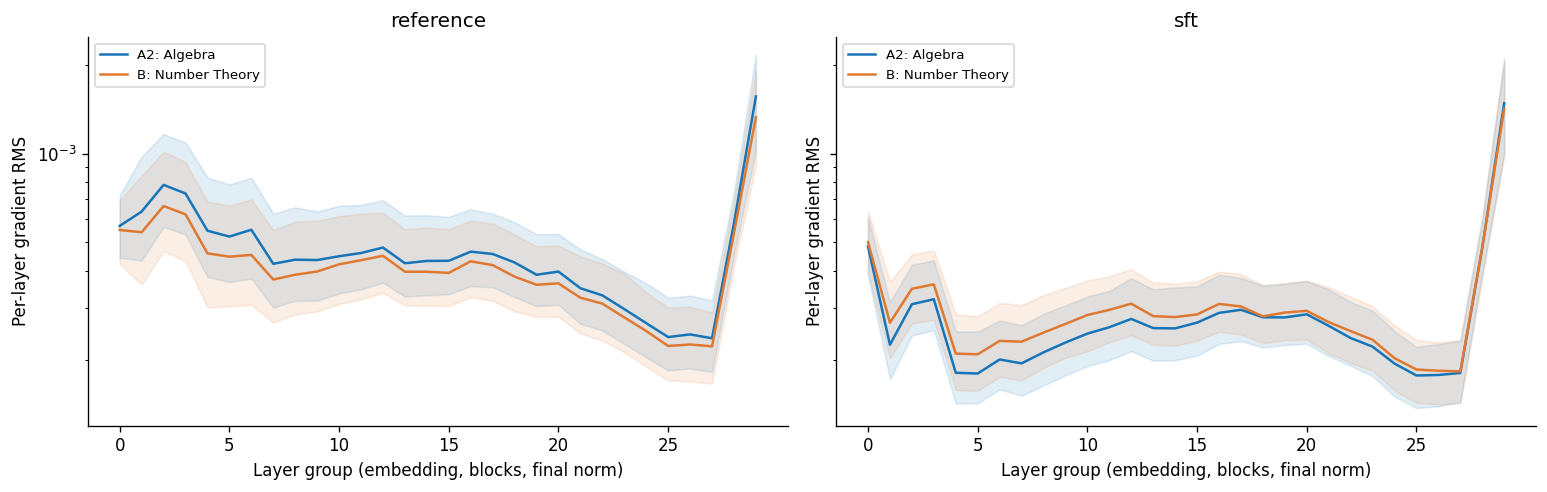

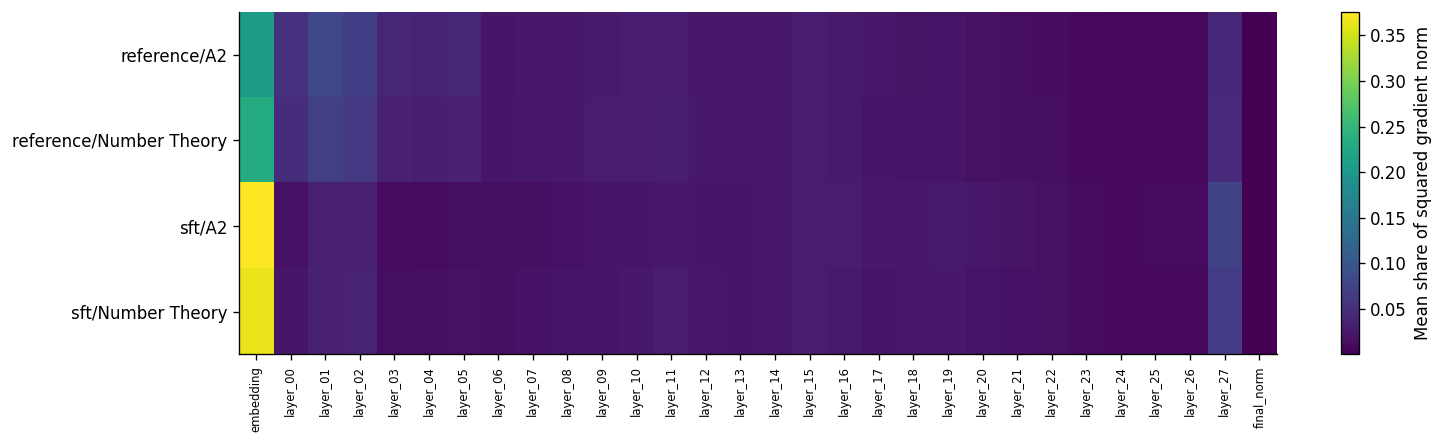

,domain,model,parameter,numel,max_abs_winner_count,max_abs_winner_fraction,grad_l2_median,grad_rms_median,grad_max_abs_median
0,A,reference,model.embed_tokens.weight,233373696,463,0.904297,8.686544,0.000569,1.772312
1,A,reference,model.layers.5.mlp.up_proj.weight,13762560,49,0.095703,2.164476,0.000583,0.567771
2,A,sft,model.embed_tokens.weight,233373696,512,1.000000,7.400305,0.000484,1.702993
3,B,reference,model.embed_tokens.weight,233373696,478,0.933594,8.413510,0.000551,1.728691
4,B,reference,model.layers.5.mlp.up_proj.weight,13762560,33,0.064453,1.778104,0.000479,0.415636
5,B,reference,model.layers.3.mlp.up_proj.weight,13762560,1,0.001953,1.889266,0.000509,0.308701
6,B,sft,model.embed_tokens.weight,233373696,512,1.000000,7.656002,0.000501,1.748340


**观测：**

A2: Algebra：平方 norm 占比最大的组为 ref 的 `embedding`（20.4%）和 SFT 的 `embedding`（37.6%）。

B: Number Theory：平方 norm 占比最大的组为 ref 的 `embedding`（23.1%）和 SFT 的 `embedding`（36.5%）。

In [15]:
gnorms = pd.concat([gd[['id','ref_grad_l2']].rename(columns={'ref_grad_l2':'global_norm'}).assign(model='reference'),
                   gd[['id','sft_grad_l2']].rename(columns={'sft_grad_l2':'global_norm'}).assign(model='sft')],ignore_index=True)
gle = gl.merge(gnorms,on=['id','model'],validate='many_to_one')
gle['energy_share'] = gle.grad_l2**2/gle.global_norm**2
np.testing.assert_allclose(gle.groupby(['id','model']).energy_share.sum(),1,rtol=1e-6,atol=1e-6)
gorder = ['embedding']+sorted(k for k in gl.layer.unique() if k.startswith('layer_'))
gorder += sorted(k for k in gl.layer.unique() if k not in gorder)
fig,axes = plt.subplots(1,2,figsize=(13,4.2),sharey=True)
for ax,model in zip(axes,['reference','sft']):
    for domain in gdomains:
        group = gl.loc[(gl.model==model)&(gl.domain==domain)].groupby('layer').grad_rms
        ax.plot(range(len(gorder)),group.median().reindex(gorder),label=gnames[domain],color=gcolors[domain])
        ax.fill_between(range(len(gorder)),group.quantile(.25).reindex(gorder),group.quantile(.75).reindex(gorder),color=gcolors[domain],alpha=.12)
    ax.set(yscale='log',xlabel='Layer group (embedding, blocks, final norm)',ylabel='Per-layer gradient RMS',title=model)
    ax.set_xticks(range(0,len(gorder),5));ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)
gshares = gle.groupby(['model','domain','layer']).energy_share.mean().unstack('layer').reindex(columns=gorder)
fig,ax = plt.subplots(figsize=(13,3.8))
heat = ax.imshow(gshares.to_numpy(),aspect='auto',cmap='viridis')
ax.set_yticks(range(len(gshares)));ax.set_yticklabels([f'{m}/{gshort[d]}' for m,d in gshares.index])
ax.set_xticks(range(len(gorder)));ax.set_xticklabels(gorder,rotation=90,fontsize=7)
fig.colorbar(heat,ax=ax,label='Mean share of squared gradient norm')
fig.tight_layout();plt.show();plt.close(fig)
top=[]
for domain,group in gd.groupby('domain'):
    for prefix,model in [('ref','reference'),('sft','sft')]:
        for parameter,count in group[f'{prefix}_grad_max_abs_parameter'].value_counts().head(3).items():
            top.append({'domain':domain,'model':model,'parameter':parameter,'max_abs_winner_count':int(count),
                        'max_abs_winner_fraction':count/len(group)})
gtop = pd.DataFrame(top).merge(gp,on=['domain','model','parameter'],validate='many_to_one')
display(gtop[['domain','model','parameter','numel','max_abs_winner_count','max_abs_winner_fraction',
              'grad_l2_median','grad_rms_median','grad_max_abs_median']].round(6))
layer_notes=[]
for domain in gdomains:
    ref_share,sft_share = gshares.loc[('reference',domain)],gshares.loc[('sft',domain)]
    layer_notes.append(f"{gnames[domain]}：平方 norm 占比最大的组为 ref 的 `{ref_share.idxmax()}`（{ref_share.max():.1%}）"
                       f"和 SFT 的 `{sft_share.idxmax()}`（{sft_share.max():.1%}）。")
display(Markdown('**观测：**\n\n'+'\n\n'.join(layer_notes)))

曲线阴影为样本间 Q25–Q75。RMS 按层参数量归一化；热图先按每条样本的全局平方 norm 归一化，
再跨样本取均值。二者分别反映每个参数的尺度和层的总贡献，不能互相替代。
`embedding` 包含绑定的输入 embedding / 输出 lm-head 合并梯度，权重只计一次。

表中列出每组最常出现全局最大单参数梯度的三个参数张量，次数和占比以该域的全部 512 条为分母。
`grad_max_abs_median` 是这个张量逐样本最大绝对梯度的中位数。
完整逐参数聚合表保存在 `gradient_parameter_summary.parquet`，逐样本逐参数明细仍在原始测量目录。

### 8.3 梯度方向与 A1 平均梯度的相似度

,模型,A1 条数,A1 平均梯度 norm,A1 平均 NLL,embedding/head 绑定
0,reference,128,9.830080,0.821362,True
1,sft,128,1.261531,0.515407,True


,数据,模型,cosine 均值,cosine 中位数,Q25,Q75,cosine > 0 比例
0,A2: Algebra,ref,0.42029,0.42710,0.31691,0.54781,1.00000
1,A2: Algebra,sft,0.02147,0.02208,-0.00748,0.05077,0.69727
2,B: Number Theory,ref,0.34019,0.33634,0.21808,0.46124,0.99609
3,B: Number Theory,sft,0.02405,0.02241,-0.00497,0.05321,0.70703


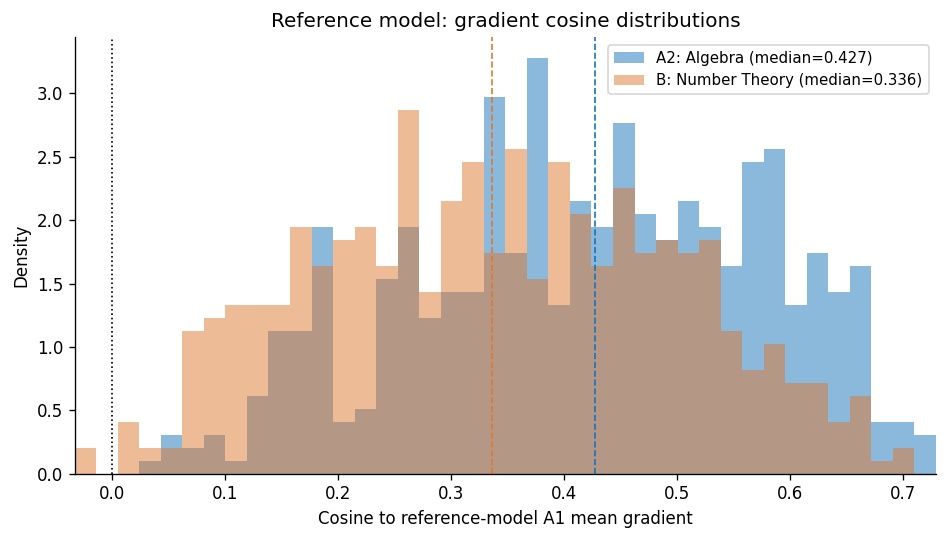

**Ref 模型上的观测：**

A2: Algebra：cosine 均值 0.4203，中位数 0.4271，100.0% 的样本与该 A1 平均梯度正向对齐。

B: Number Theory：cosine 均值 0.3402，中位数 0.3363，99.6% 的样本与该 A1 平均梯度正向对齐。

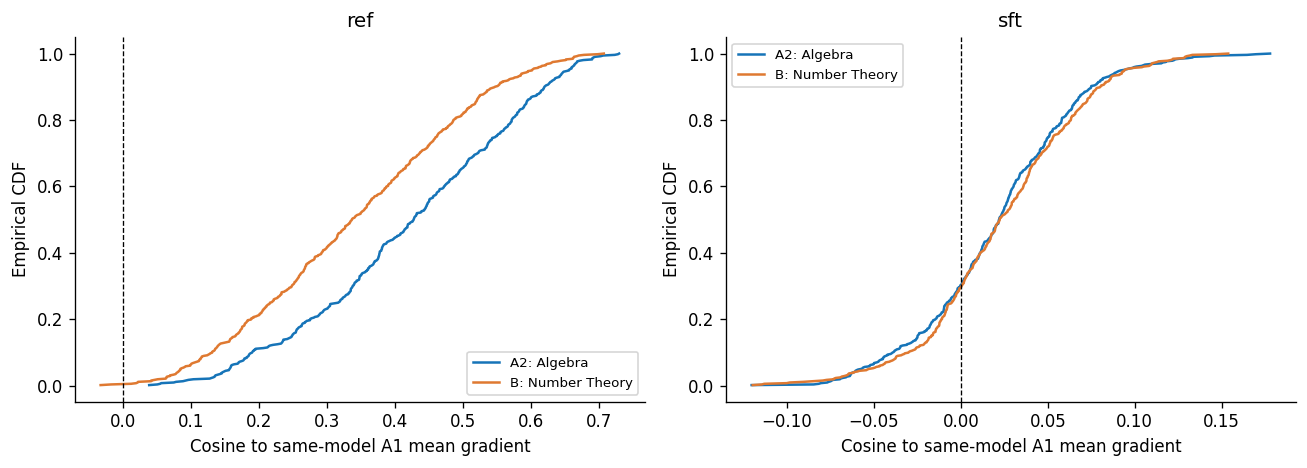

In [16]:
display(pd.DataFrame([{'模型':k,'A1 条数':len(v['ids']),'A1 平均梯度 norm':v['norm'],
                      'A1 平均 NLL':v['mean_nll'],'embedding/head 绑定':v['tied_input_output_embeddings']}
                     for k,v in gm['anchor_summary'].items()]).round(6))
cosine_rows=[]
for domain,group in gd.groupby('domain'):
    for prefix in ['ref','sft']:
        values = group[f'{prefix}_cos_to_a1']
        cosine_rows.append({'数据':gnames[domain],'模型':prefix,'cosine 均值':values.mean(),
                            'cosine 中位数':values.median(),'Q25':values.quantile(.25),'Q75':values.quantile(.75),
                            'cosine > 0 比例':(values>0).mean()})
display(pd.DataFrame(cosine_rows).round(5))
# Both distributions use the same mean A1 gradient at the reference model.
ref_cosine_bins = np.histogram_bin_edges(gd['ref_cos_to_a1'],bins=40)
fig,ax = plt.subplots(figsize=(8,4.6))
ref_cosine_notes=[]
for domain,group in gd.groupby('domain'):
    values = group['ref_cos_to_a1']
    assert np.histogram(values,bins=ref_cosine_bins)[0].sum()==len(values)
    ax.hist(values,bins=ref_cosine_bins,density=True,alpha=.5,color=gcolors[domain],
            label=f'{gnames[domain]} (median={values.median():.3f})')
    ax.axvline(values.median(),color=gcolors[domain],linestyle='--',linewidth=1)
    ref_cosine_notes.append(f"{gnames[domain]}：cosine 均值 {values.mean():.4f}，中位数 {values.median():.4f}，"
                            f"{(values>0).mean():.1%} 的样本与该 A1 平均梯度正向对齐。")
ax.axvline(0,color='black',linestyle=':',linewidth=1)
ax.set(xlim=(ref_cosine_bins[0],ref_cosine_bins[-1]),xlabel='Cosine to reference-model A1 mean gradient',
       ylabel='Density',title='Reference model: gradient cosine distributions')
ax.legend(fontsize=9);fig.tight_layout();plt.show();plt.close(fig)
display(Markdown('**Ref 模型上的观测：**\n\n'+'\n\n'.join(ref_cosine_notes)))
fig,axes = plt.subplots(1,2,figsize=(11,4))
for ax,prefix in zip(axes,['ref','sft']):
    for domain,group in gd.groupby('domain'):
        values = np.sort(group[f'{prefix}_cos_to_a1'])
        ax.plot(values,np.arange(1,len(values)+1)/len(values),label=gnames[domain],color=gcolors[domain])
    ax.axvline(0,color='black',linestyle='--',linewidth=.8)
    ax.set(title=prefix,xlabel='Cosine to same-model A1 mean gradient',ylabel='Empirical CDF')
    ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)

新增直方图比较 `cos(g_ref(A2 样本), mean g_ref(A1))` 和
`cos(g_ref(对照域样本), mean g_ref(A1))`。先对固定 128 条 A1 的梯度求均值，再计算每条样本的 cosine，
因而两组使用同一个 ref 参照向量。两域使用共同分桶，密度分别归一化；彩色虚线为中位数，黑色点线为零。

下方 CDF 的两模型使用同一批 128 条 A1，但平均梯度分别在各自参数位置计算，所以参照向量会改变。
这里的两个 cosine 不是 `cos(g_ref(x), g_sft(x))`，也不是相对同一个固定向量的前后夹角变化。

在单步、足够小的普通梯度下降近似下，正向对齐意味着沿样本的负梯度更新可能降低该 A1 子集的平均 loss。
实际 AdamW 更新还受预条件、动量和有限步长影响；而 A1 是训练数据，因此这个参照也不能替代未见目标域上的训练收益验证。

### 8.4 与 loss、长度的关系及区分信息

,domain,model,"rho(norm,NLL)","rho(norm,prompt length)","rho(norm,response length)"
0,A,ref,0.4248,-0.3656,-0.8736
1,A,sft,0.4084,-0.1723,-0.7054
2,B,ref,0.2951,-0.2688,-0.8991
3,B,sft,0.3208,-0.1530,-0.7963


,domain,"rho(norm drop,loss decrease)","rho(norm drop,relative decrease)"
0,A,0.8190,0.7634
1,B,0.7871,0.7607


以上均为域内 Spearman 相关；loss 下降量与相对下降比例分别报告。
长度匹配沿用上文样本： {'A': 404, 'B': 404}


,raw AUC,raw 95% CI,length_matched AUC,length_matched 95% CI
梯度特征,,,,
ref_grad_l2,0.5650,"[0.5285, 0.5996]",0.4964,"[0.4561, 0.5383]"
sft_grad_l2,0.4561,"[0.4203, 0.4921]",0.3839,"[0.3457, 0.4246]"
grad_l2_delta,0.6403,"[0.6061, 0.6740]",0.6007,"[0.5616, 0.6413]"
ref_grad_max_abs,0.5212,"[0.4851, 0.5561]",0.4534,"[0.4143, 0.4934]"
sft_grad_max_abs,0.4795,"[0.4452, 0.5152]",0.4236,"[0.3845, 0.4633]"
grad_max_abs_delta,0.5928,"[0.5582, 0.6243]",0.5756,"[0.5348, 0.6120]"
ref_cos_to_a1,0.6404,"[0.6048, 0.6738]",0.6269,"[0.5886, 0.6658]"
sft_cos_to_a1,0.4815,"[0.4463, 0.5168]",0.4849,"[0.4461, 0.5244]"


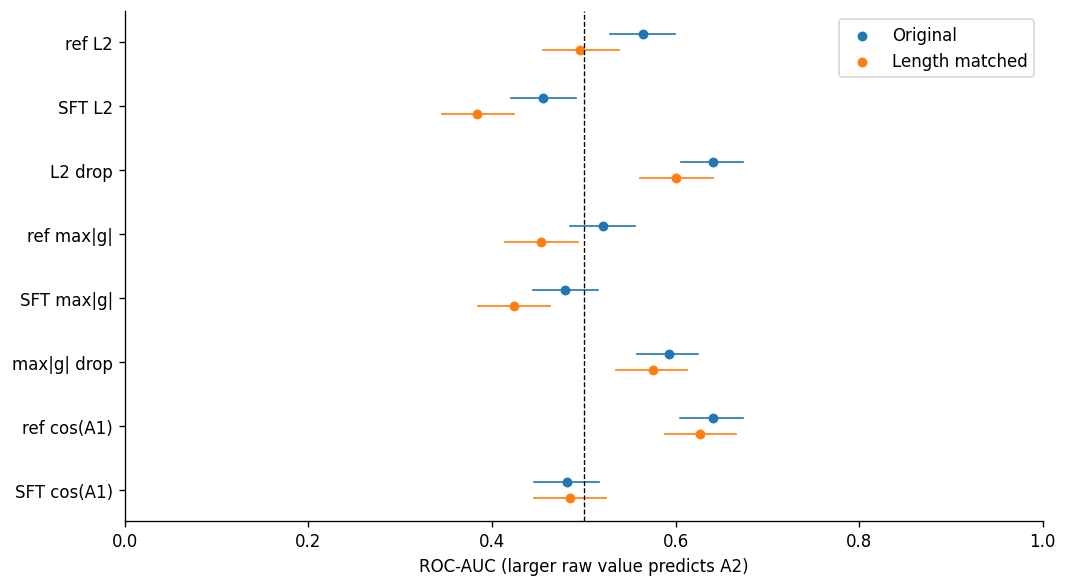

In [17]:
display(pd.DataFrame(gm['norm_correlations']).rename(columns={'nll':'rho(norm,NLL)',
    'prompt_tokens':'rho(norm,prompt length)','response_tokens':'rho(norm,response length)'}).round(4))
display(pd.DataFrame(gm['norm_drop_loss_correlations']).rename(columns={
    'delta_loss':'rho(norm drop,loss decrease)','relative_gain':'rho(norm drop,relative decrease)'}).round(4))
print('以上均为域内 Spearman 相关；loss 下降量与相对下降比例分别报告。')
print('长度匹配沿用上文样本：',gm['length_matched_counts'])
gkeys = ['ref_grad_l2','sft_grad_l2','grad_l2_delta','ref_grad_max_abs','sft_grad_max_abs',
         'grad_max_abs_delta','ref_cos_to_a1','sft_cos_to_a1']
glabels = ['ref L2','SFT L2','L2 drop','ref max|g|','SFT max|g|','max|g| drop','ref cos(A1)','SFT cos(A1)']
def ginterval(v): return f'[{v[0]:.4f}, {v[1]:.4f}]'
auc_rows=[]
for key in gkeys:
    row={'梯度特征':key}
    for pool,frame in [('raw',gd),('length_matched',gmatched)]:
        saved = gm['comparisons'][pool]['gradient_scores'][key]
        np.testing.assert_allclose(roc_auc_score(frame.domain=='A',frame[key]),saved['roc_auc'],rtol=0,atol=1e-12)
        row[f'{pool} AUC'] = round(saved['roc_auc'],4)
        row[f'{pool} 95% CI'] = ginterval(saved['roc_auc_ci95'])
    auc_rows.append(row)
display(pd.DataFrame(auc_rows).set_index('梯度特征'))
fig,ax = plt.subplots(figsize=(9,5))
for shift,pool,label in [(-.12,'raw','Original'),(.12,'length_matched','Length matched')]:
    for i,key in enumerate(gkeys):
        value = gm['comparisons'][pool]['gradient_scores'][key]
        lo,hi = value['roc_auc_ci95'];point = value['roc_auc']
        ax.plot([lo,hi],[i+shift,i+shift],color=('C0' if pool=='raw' else 'C1'),linewidth=1)
        ax.scatter(point,i+shift,color=('C0' if pool=='raw' else 'C1'),label=label if i==0 else None,s=24)
ax.axvline(.5,color='black',linestyle='--',linewidth=.8)
ax.set(xlim=(0,1),yticks=range(len(gkeys)),yticklabels=glabels,xlabel='ROC-AUC (larger raw value predicts A2)')
ax.invert_yaxis();ax.legend();fig.tight_layout();plt.show();plt.close(fig)

A2 固定为正类，所有梯度特征采用“数值越大越倾向 A2”，没有看到结果后翻转方向。
AUC 小于 0.5 表示较大值更倾向另一组，并不等于没有区分信息。
区间来自按域分层、按问题组抽样的 2,000 次 bootstrap；这些多指标结果属于探索性诊断。
长度对照沿用本 notebook 上文的匹配 ID，并未重新挑选适合梯度的样本。

### 8.5 本轮观察与解释边界

In [18]:
observations=[]
for domain,group in gd.groupby('domain'):
    loss_drop = group.delta_loss.mean()
    norm_drop = (1-group.sft_grad_l2/group.ref_grad_l2).median()
    observations.append(f"{gnames[domain]}：平均 loss 变化量（ref−SFT）为 {loss_drop:.4f}，"
                         f"配对 norm 相对下降的中位数为 {norm_drop:.1%}。")
    if loss_drop<0 and norm_drop>0:
        observations.append(f"{gnames[domain]} 的平均 loss 上升，但 norm 的配对中位变化仍为下降；梯度变小与 loss 改善并非等价。")
for key,label in [('ref_grad_l2','训练前 norm'),('sft_grad_l2','训练后 norm'),
                  ('ref_cos_to_a1','训练前 A1 cosine'),('sft_cos_to_a1','训练后 A1 cosine')]:
    graw_result = gm['comparisons']['raw']['gradient_scores'][key]
    gmatched_result = gm['comparisons']['length_matched']['gradient_scores'][key]
    low,high = gmatched_result['roc_auc_ci95']
    direction = ('在该匹配子集中，较大值倾向 A2' if low>.5 else
                 f'在该匹配子集中，较大值倾向 {gnames[gdomains[1]]}' if high<.5 else
                 '该匹配子集的区间覆盖 0.5，尚无稳定的区分证据')
    observations.append(f"{label}：原始 AUC {graw_result['roc_auc']:.4f}；长度匹配 AUC {gmatched_result['roc_auc']:.4f} "
                         f"（95% CI {ginterval(gmatched_result['roc_auc_ci95'])}）；{direction}。")
    raw_low,raw_high = graw_result['roc_auc_ci95']
    if key=='ref_grad_l2' and (raw_low>.5 or raw_high<.5) and low<=.5<=high:
        observations.append('训练前 norm 在原始池中的区分信号未在长度对照中稳定保留。匹配也改变了评估人群，不能把差异全部归因于长度。')
display(Markdown('**观测结果：**\n\n'+'\n\n'.join(observations)))

**观测结果：**

A2: Algebra：平均 loss 变化量（ref−SFT）为 0.1719，配对 norm 相对下降的中位数为 35.1%。

B: Number Theory：平均 loss 变化量（ref−SFT）为 0.1008，配对 norm 相对下降的中位数为 23.6%。

训练前 norm：原始 AUC 0.5650；长度匹配 AUC 0.4964 （95% CI [0.4561, 0.5383]）；该匹配子集的区间覆盖 0.5，尚无稳定的区分证据。

训练前 norm 在原始池中的区分信号未在长度对照中稳定保留。匹配也改变了评估人群，不能把差异全部归因于长度。

训练后 norm：原始 AUC 0.4561；长度匹配 AUC 0.3839 （95% CI [0.3457, 0.4246]）；在该匹配子集中，较大值倾向 B: Number Theory。

训练前 A1 cosine：原始 AUC 0.6404；长度匹配 AUC 0.6269 （95% CI [0.5886, 0.6658]）；在该匹配子集中，较大值倾向 A2。

训练后 A1 cosine：原始 AUC 0.4815；长度匹配 AUC 0.4849 （95% CI [0.4461, 0.5244]）；该匹配子集的区间覆盖 0.5，尚无稳定的区分证据。

**解释边界：** norm 衡量局部梯度大小，cosine 描述相对指定 A1 参照的方向；单独任何一个都不能当作
“继续训练这个样本的收益”。层间占比、回答长度、loss 尺度和来源/格式差异需要一起看。
尤其要区分原始池与长度匹配子集的结论，匹配后的区间不包含训练 seed 的不确定性。
要验证选数效用，仍需固定预算进行实际选数训练，并在未参与选择的目标域测试集上评估。